# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [1]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Кузнєцов Макар'      # прізвище та ім'я
GROUP        = 'ШІ-32'      # шифр групи, наприклад СШІ-31
NUMBER       = 8       # ваш номер за списком групи (1–30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Кузнєцов Макар | ШІ-32 | номер 8


In [2]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 8   ·   Кузнєцов Макар   ·   ШІ-32

   Ринок:  Odesa
   Товар:  сметана   (у наборі даних: Sour cream - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | 30.10.2026 |
| **Підпис** | Кузнєцов |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [3]:
# Завдання 1. Підготовка ряду
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (11, 3.6)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = .25

prices = pd.read_csv('ціни_україна_2014_2017.csv')
prices['date'] = pd.to_datetime(dict(year=prices['рік'], month=prices['місяць'], day=1))

GRID = pd.date_range('2014-03-01', '2017-12-01', freq='MS')
raw = (prices[(prices['ринок'] == MARKET) & (prices['товар'] == GOOD)]
       .set_index('date')['ціна'].sort_index().reindex(GRID))

print('Місяців у сітці:     ', len(GRID))
print('Місяців із виміром:  ', raw.notna().sum())
gap = raw[raw.isna()].index
print('Пропущені місяці:    ', [d.strftime('%m.%Y') for d in gap])

# чи пропуск цього місяця є в усьому наборі, а не лише в моєму ряді
per_month = prices.groupby('date').size().reindex(GRID, fill_value=0)
print('Рядків у наборі за пропущений місяць:', per_month[gap].tolist())
print('Рядків у наборі в сусідні місяці:    ',
      per_month[gap[0] - pd.DateOffset(months=1)], per_month[gap[0] + pd.DateOffset(months=1)])

Місяців у сітці:      46
Місяців із виміром:   45
Пропущені місяці:     ['08.2017']
Рядків у наборі за пропущений місяць: [0]
Рядків у наборі в сусідні місяці:     650 650


**Висновок до завдання 1:**

1. Повна місячна сітка 03.2014 – 12.2017 містить **46 місяців**, вимір є для **45**.
2. Пропущено **серпень 2017 (08.2017)**.
3. Пропуск виник не через мій ринок: за 08.2017 у всьому наборі **0 рядків**, тоді як у липні й вересні 2017 — по 650.
   Тобто за цей місяць дані просто не були зібрані чи опубліковані джерелом, для всіх ринків і товарів одночасно.
   У моєму ряді пропуск **один**. Без `reindex` на повну сітку його не видно: ряд має 45 рядків, `isna()` дає 0, і серпень мовчки «зникає».

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [4]:
# Завдання 2. Заповнення пропуску
# третій спосіб: сезонна інтерполяція — лінійна інтерполяція ряду без сезонної
# складової (з класичного розкладання на 12 міс.), потім сезон повертається назад
from statsmodels.tsa.seasonal import seasonal_decompose
tmp = raw.interpolate()
seas = seasonal_decompose(tmp, model='additive', period=12).seasonal
fill = pd.DataFrame({
    'перенесення останнього (ffill)': raw.ffill(),
    'лінійна інтерполяція':           raw.interpolate(method='linear'),
    'сезонна інтерполяція':           (raw - seas).interpolate() + seas,
})

print(fill.loc[gap[0] - pd.DateOffset(months=1): gap[0] + pd.DateOffset(months=1)].round(3).to_string())

y = raw.interpolate(method='linear')        # обраний спосіб
y.name = 'price'
assert y.isna().sum() == 0 and len(y) == 46

# приклад, коли заповнювати не можна: ринки, що зникають із набору у 2014
last_obs = prices.groupby('ринок')['date'].max()
print()
print('Ринки, останнє спостереження яких раніше за 12.2017:')
print(last_obs[last_obs < '2017-12-01'].dt.strftime('%m.%Y').to_string())

            перенесення останнього (ffill)  лінійна інтерполяція  сезонна інтерполяція
2017-07-01                          44.827                44.827                44.827
2017-08-01                          44.827                44.813                44.426
2017-09-01                          44.800                44.800                44.800

Ринки, останнє спостереження яких раніше за 12.2017:
ринок
Crimea           03.2014
m. Sevastopol    04.2014


**Висновок до завдання 2:**

1. Значення для 08.2017: перенесення останнього — **44.827** грн; лінійна інтерполяція — **44.813** грн;
   сезонна інтерполяція (лінійна інтерполяція ряду без сезонної складової, потім сезон повертається) — **44.426** грн.
2. Обираю **лінійну інтерполяцію**. Сусідні значення майже однакові (липень 44.83, вересень 44.80), і середина між ними —
   найменш «вигадане» значення. Сезонна інтерполяція створює просідання на 0.4 грн, якого сусіди не підтверджують.
   До того ж сезонну складову оцінено лише за ~4 роки. Різниця між способами менша за 1 %, тож вибір на подальший аналіз майже не впливає.
3. Заповнювати **неприпустимо**, коли пропуск означає, що об'єкта спостереження більше немає, а не що один вимір загубився.
   Приклад із набору: **Крим** (останнє спостереження 03.2014) і **Севастополь** (04.2014) після анексії зникають із набору.
   «Заповнити» для них 44 місяці означало б вигадати дані, яких ніхто не збирав. Так само не можна заповнювати
   довгі пропуски на початку чи в кінці ряду, бо це вже екстраполяція.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

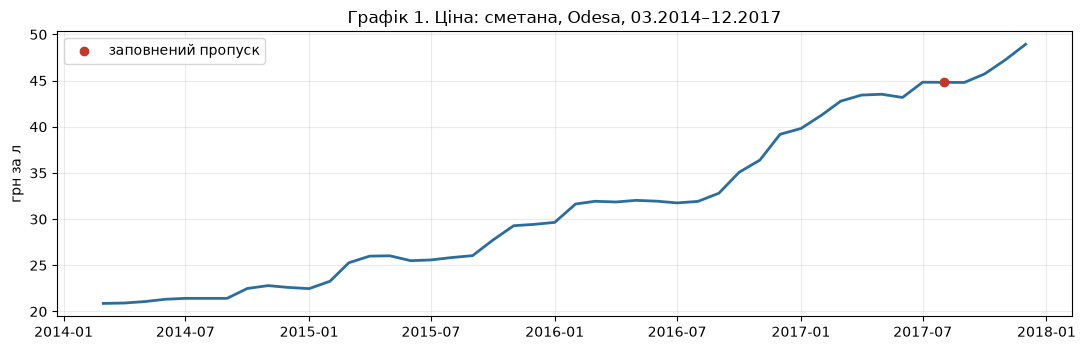

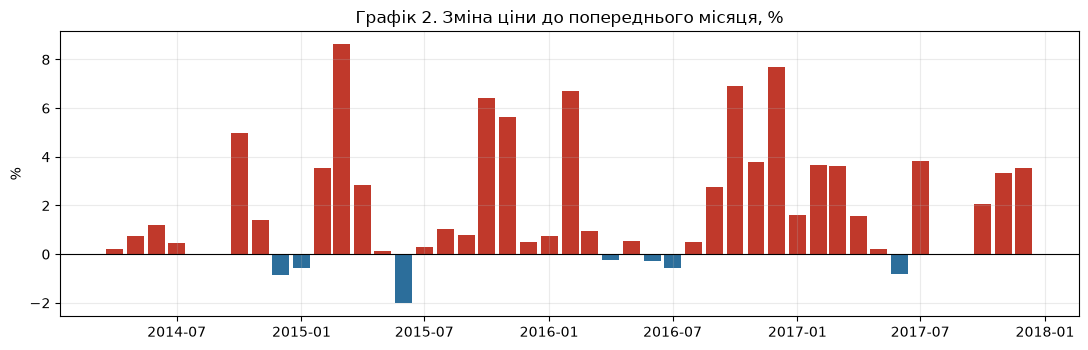

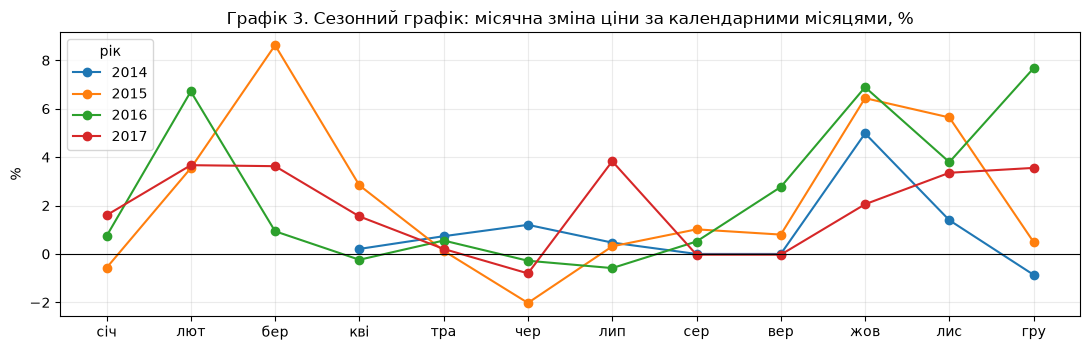

Середня місячна зміна, % (жовт–бер): 3.54
Середня місячна зміна, % (кві–вер):  0.55
Місяців зі зниженням ціни: 9 з 45


In [5]:
# Завдання 3. Візуальна розвідка
fig, ax = plt.subplots()
ax.plot(y.index, y.values, lw=2, color='#2C6E9B')
ax.scatter(gap, y[gap], color='#C0392B', zorder=5, label='заповнений пропуск')
ax.set_title(f'Графік 1. Ціна: {GOOD_UA}, {MARKET}, 03.2014–12.2017')
ax.set_ylabel('грн за л'); ax.legend()
plt.tight_layout(); plt.show()

mom = y.pct_change() * 100
fig, ax = plt.subplots()
ax.bar(mom.index, mom.values, width=25,
       color=np.where(mom.values >= 0, '#C0392B', '#2C6E9B'))
ax.axhline(0, color='black', lw=.8)
ax.set_title('Графік 2. Зміна ціни до попереднього місяця, %'); ax.set_ylabel('%')
plt.tight_layout(); plt.show()

mom_df = pd.DataFrame({'рік': mom.index.year, 'місяць': mom.index.month, 'зміна': mom.values}).dropna()
fig, ax = plt.subplots()
for yr, g in mom_df.groupby('рік'):
    ax.plot(g['місяць'], g['зміна'], marker='o', lw=1.5, label=str(yr))
ax.axhline(0, color='black', lw=.8)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(['січ', 'лют', 'бер', 'кві', 'тра', 'чер', 'лип', 'сер', 'вер', 'жов', 'лис', 'гру'])
ax.set_title('Графік 3. Сезонний графік: місячна зміна ціни за календарними місяцями, %')
ax.set_ylabel('%'); ax.legend(title='рік')
plt.tight_layout(); plt.show()

print('Середня місячна зміна, % (жовт–бер):', round(mom_df[mom_df['місяць'].isin([10, 11, 12, 1, 2, 3])]['зміна'].mean(), 2))
print('Середня місячна зміна, % (кві–вер): ', round(mom_df[mom_df['місяць'].isin([4, 5, 6, 7, 8, 9])]['зміна'].mean(), 2))
print('Місяців зі зниженням ціни:', (mom < 0).sum(), 'з', mom.notna().sum())

**Висновок до завдання 3:**

1. **Графік 1 (лінія, лінійна шкала, грн).** Питання: як змінювався рівень ціни з часом? Час упорядкований і неперервний,
   тому лінія — вона показує і тренд, і плато. Шкала лінійна, бо важлива абсолютна ціна в грн. Вісь Y не від нуля:
   у лінії значення кодується положенням, а не довжиною, тож нуль не потрібен.
2. **Графік 2 (стовпці, %, від нуля).** Питання: у які місяці ціна стрибала, а в які стояла? Помісячна зміна — це окремі прирости
   відносно нуля, тому стовпці від нульової лінії. Колір показує знак. Шкала у відсотках, щоб зміни 2014 року (ціна ~21 грн)
   можна було порівнювати зі змінами 2017 року (~45 грн).
3. **Графік 3 (сезонний графік: вісь X — календарний місяць, одна лінія на рік).** Питання: чи стрибки прив'язані до календаря?
   Якщо так, лінії різних років збігаються піками в тих самих місяцях. Тому по осі X календарний місяць, а не дата.

**Неочікувана знахідка:** майже все подорожчання припадає на **жовтень–березень** (середня зміна +3.54 % за місяць),
а з квітня по вересень ціна майже стоїть (+0.55 %). Ціна знижувалась лише в 9 місяцях із 45, і всі вони не більші за 2 %.
Тобто ряд — це «сходинки» щозими, а не рівномірне зростання.

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

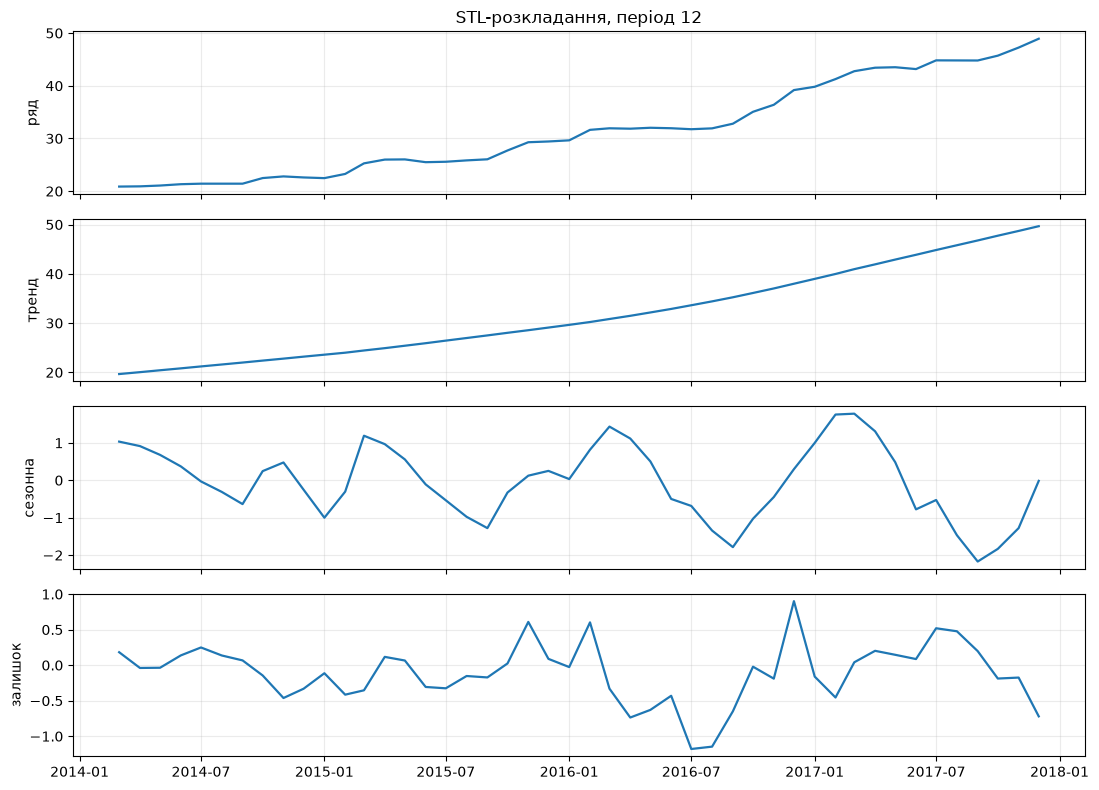

Сила сезонності F_S = 0.856
Сила тренду     F_T = 0.998
Поріг: 0.64
Частка шуму в розкиді «сезон + залишок»: 0.144
Амплітуда сезонної складової, грн: 3.95

Середня сезонна складова за календарним місяцем, грн:
1     0.01
2     0.76
3     1.36
4     1.08
5     0.56
6    -0.25
7    -0.44
8    -1.02
9    -1.47
10   -0.74
11   -0.28
12    0.07


In [6]:
# Завдання 4. Розкладання на складові
from statsmodels.tsa.seasonal import STL

stl = STL(y, period=12).fit()

fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
for ax, comp, title in zip(axes, [stl.observed, stl.trend, stl.seasonal, stl.resid],
                           ['ряд', 'тренд', 'сезонна', 'залишок']):
    ax.plot(comp.index, comp.values, lw=1.6)
    ax.set_ylabel(title)
axes[0].set_title('STL-розкладання, період 12')
plt.tight_layout(); plt.show()

F_S = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
F_T = max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
print(f'Сила сезонності F_S = {F_S:.3f}')
print(f'Сила тренду     F_T = {F_T:.3f}')
print('Поріг: 0.64')
print(f'Частка шуму в розкиді «сезон + залишок»: {stl.resid.var() / (stl.seasonal + stl.resid).var():.3f}')
print('Амплітуда сезонної складової, грн:', round(stl.seasonal.max() - stl.seasonal.min(), 2))
print()
print('Середня сезонна складова за календарним місяцем, грн:')
print(stl.seasonal.groupby(stl.seasonal.index.month).mean().round(2).to_string())

**Висновок до завдання 4:**

1. Чотирипанельний графік — вище.
2. **F_S = 0.856**, **F_T = 0.998**.
3. **Сезонність є.** F_S = 0.856 — велике значення,
   близьке до 1, і більше за поріг 0.64: шум займає лише 14% розкиду «сезон + залишок», решту пояснює сезонна складова, тож це не шум. Вона узгоджується з графіком 3: рівень вищий за тренд у лютому–квітні (до +1.36 грн у березні),
   після зимових стрибків, і нижчий у липні–жовтні (до −1.47 грн у вересні), перед ними. Амплітуда 3.95 грн.
   Тренд дуже сильний (F_T ≈ 1), він домінує в ряді. Застереження: у ряді лише ~3.8 сезонних циклів, тому форма сезону оцінена грубо.

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

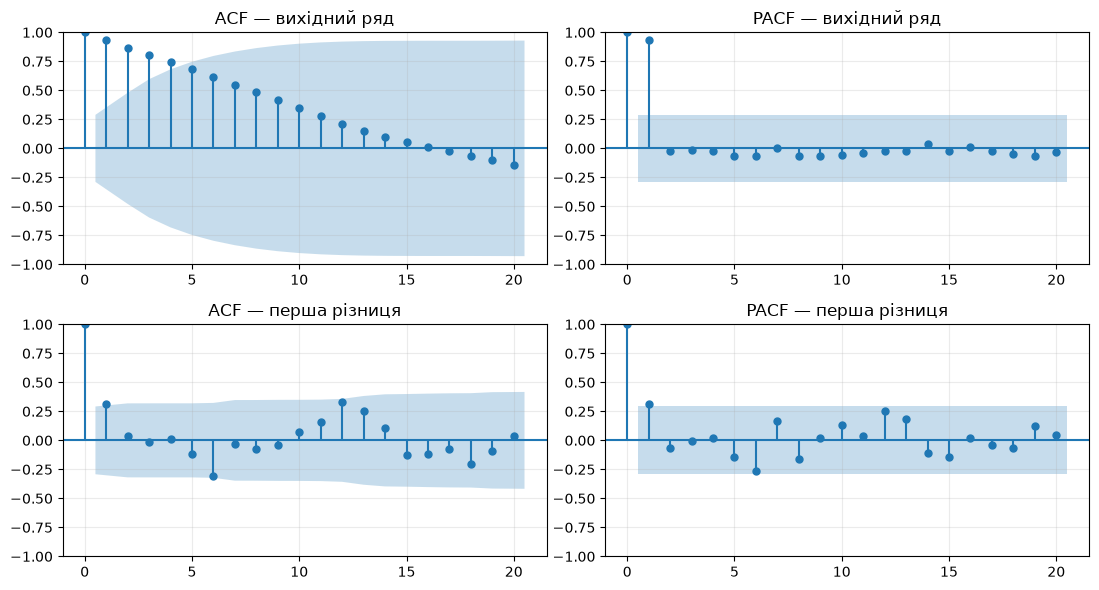

               ADF p (H0: є одиничний корінь)  KPSS p (H0: стаціонарний)
ряд                                                                     
вихідний ряд                           0.9951                     0.0100
перша різниця                          0.0002                     0.0954

Межа значущості ACF ±1.96/√n для першої різниці: 0.292


/var/folders/r5/hc3sq99s5w54t54hjqhdsmmm0000gn/T/ipykernel_17685/735878199.py:18: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  'KPSS p (H0: стаціонарний)':     kpss(x, regression='c', nlags='auto')[1]})


In [7]:
# Завдання 5. Стаціонарність
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss

dy = y.diff().dropna()

fig, axes = plt.subplots(2, 2, figsize=(11, 6))
plot_acf(y,   lags=20, ax=axes[0, 0], title='ACF — вихідний ряд')
plot_pacf(y,  lags=20, ax=axes[0, 1], title='PACF — вихідний ряд', method='ywm')
plot_acf(dy,  lags=20, ax=axes[1, 0], title='ACF — перша різниця')
plot_pacf(dy, lags=20, ax=axes[1, 1], title='PACF — перша різниця', method='ywm')
plt.tight_layout(); plt.show()

rows = []
for name, x in [('вихідний ряд', y), ('перша різниця', dy)]:
    rows.append({'ряд': name,
                 'ADF p (H0: є одиничний корінь)': adfuller(x, autolag='AIC')[1],
                 'KPSS p (H0: стаціонарний)':     kpss(x, regression='c', nlags='auto')[1]})
stat_tab = pd.DataFrame(rows).set_index('ряд')
print(stat_tab.round(4).to_string())
print()
print('Межа значущості ACF ±1.96/√n для першої різниці:', round(1.96 / np.sqrt(len(dy)), 3))

**Висновок до завдання 5:**

1. Графіки ACF/PACF — вище. Вихідний ряд: ACF спадає дуже повільно (0.93, 0.87, 0.81, …), PACF має один пік на лагу 1 (0.95).
   Це типова картина одиничного кореня. Перша різниця: ACF на лагу 1 = 0.31 (межа ±0.29), на лагах 6 і 12 = −0.31 і 0.33.
2. Таблиця:

| ряд | ADF p (H0: одиничний корінь) | KPSS p (H0: стаціонарність) |
|---|---|---|
| вихідний | 0.995 | ≤ 0.01 |
| перша різниця | 0.0002 | 0.095 |

3. **Вихідний ряд нестаціонарний**: ADF не відхиляє H0 про одиничний корінь (p = 0.995), KPSS відхиляє H0 про стаціонарність (p ≤ 0.01).
   **Перша різниця стаціонарна**: ADF відхиляє одиничний корінь (p = 0.0002), KPSS не відхиляє стаціонарність (p = 0.095 > 0.05).
   **Тести узгоджуються** для обох рядів. Отже, d = 1, другого диференціювання не потрібно.
4. Розбіжності немає. (Для KPSS на вихідному ряді statsmodels попереджає, що справжнє p ще менше за 0.01. Висновок від цього не змінюється.)

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [8]:
# Завдання 6. Базисні прогнози та ретроспективна перевірка
N_FOLDS, H = 7, 3
n = len(y)
vals = y.values

def f_naive(train, h, t0):  return np.repeat(train[-1], h)
def f_snaive(train, h, t0): return np.array([train[len(train) - 12 + i] for i in range(h)])
def f_mean(train, h, t0):   return np.repeat(train.mean(), h)
def f_drift(train, h, t0):
    slope = (train[-1] - train[0]) / (len(train) - 1)
    return train[-1] + slope * np.arange(1, h + 1)

BASELINES = {'наївний': f_naive, 'сезонний наївний': f_snaive,
             'середнє': f_mean, 'дрейф': f_drift}

# фолд k: навчання на перших n - k*H точках, перевірка на наступних H
FOLDS = [(n - k * H, n - k * H + H) for k in range(1, N_FOLDS + 1)]
print('Фолди (навчання → перевірка):')
for a, b in FOLDS:
    print(f'   {y.index[0]:%m.%Y}–{y.index[a-1]:%m.%Y} ({a} міс.)  →  {y.index[a]:%m.%Y}–{y.index[b-1]:%m.%Y}')

def metrics(true, pred):
    true, pred = np.asarray(true), np.asarray(pred)
    e = true - pred
    return {'MAE': np.mean(np.abs(e)), 'RMSE': np.sqrt(np.mean(e ** 2)),
            'MAPE, %': np.mean(np.abs(e) / np.abs(true)) * 100}

def rolling_cv(forecaster):
    true, pred = [], []
    for a, b in FOLDS:
        true.extend(vals[a:b]); pred.extend(forecaster(vals[:a], H, a))
    return np.array(true), np.array(pred)

cv_tab = pd.DataFrame({name: metrics(*rolling_cv(f)) for name, f in BASELINES.items()}).T
print()
print('Рухомий початок, 7 фолдів × 3 кроки:')
print(cv_tab.round(3).to_string())

# Для порівняння — звичайний випадковий поділ 75/25.
# Тестові місяці випадкові, а «навчальні» — усі інші, зокрема й пізніші за тестовий.
rng = np.random.default_rng(42)
test_idx = np.sort(rng.choice(np.arange(12, n), size=round(.25 * n), replace=False))
train_idx = np.setdiff1d(np.arange(n), test_idx)

def random_pred(name, t):
    tr = train_idx
    if name == 'наївний':          return vals[tr[tr < t].max()]
    if name == 'сезонний наївний': return vals[t - 12] if (t - 12) in tr else vals[tr[tr < t].max()]
    if name == 'середнє':          return vals[tr].mean()
    if name == 'дрейф':            # пряма через першу й останню навчальні точки (остання — у майбутньому)
        return vals[tr[0]] + (vals[tr[-1]] - vals[tr[0]]) / (tr[-1] - tr[0]) * (t - tr[0])

rnd_tab = pd.DataFrame({name: metrics(vals[test_idx], [random_pred(name, t) for t in test_idx])
                        for name in BASELINES}).T
print()
print('Випадковий поділ 75/25 (seed 42), тест:', [y.index[i].strftime('%m.%y') for i in test_idx])
print(rnd_tab.round(3).to_string())
print()
print('У скільки разів MAE на рухомому початку більший за MAE випадкового поділу:')
print((cv_tab['MAE'] / rnd_tab['MAE']).round(2).to_string())

Фолди (навчання → перевірка):
   03.2014–09.2017 (43 міс.)  →  10.2017–12.2017
   03.2014–06.2017 (40 міс.)  →  07.2017–09.2017
   03.2014–03.2017 (37 міс.)  →  04.2017–06.2017
   03.2014–12.2016 (34 міс.)  →  01.2017–03.2017
   03.2014–09.2016 (31 міс.)  →  10.2016–12.2016
   03.2014–06.2016 (28 міс.)  →  07.2016–09.2016
   03.2014–03.2016 (25 міс.)  →  04.2016–06.2016

Рухомий початок, 7 фолдів × 3 кроки:
                     MAE    RMSE  MAPE, %
наївний            1.621   2.292    3.919
сезонний наївний   9.319   9.625   23.142
середнє           12.202  12.828   29.903
дрейф              1.193   1.666    3.056

Випадковий поділ 75/25 (seed 42), тест: ['05.15', '06.15', '09.15', '02.16', '07.16', '08.16', '09.16', '11.16', '03.17', '05.17', '07.17', '12.17']
                    MAE   RMSE  MAPE, %
наївний           0.837  1.103    2.243
сезонний наївний  6.340  7.112   17.971
середнє           7.056  9.073   18.231
дрейф             3.313  4.048   10.914

У скільки разів MAE на рухом

**Висновок до завдання 6:**

1. Рухомий початок, 7 фолдів × 3 кроки:

| базис | MAE | RMSE | MAPE, % |
|---|---|---|---|
| наївний | 1.621 | 2.292 | 3.92 |
| сезонний наївний | 9.319 | 9.625 | 23.14 |
| середнє | 12.202 | 12.828 | 29.90 |
| **дрейф** | **1.193** | **1.666** | **3.06** |

2. Найкращий — **дрейф**. Ряд має дуже сильний і стійкий тренд (F_T = 0.998), а ціна майже ніколи не падає.
   Тому «останнє значення + середній приріст» точніший за просто «останнє значення» (наївний).
   Сезонний наївний і середнє ігнорують тренд. Сезонний наївний бере ціну рік тому, а вона в середньому на ~7 грн нижча,
   звідси MAE ≈ 9 грн. Сезонність є (завдання 4), але на горизонті 3 місяці її ефект значно менший за річне зростання.
3. Випадковий поділ 75/25 (seed 42) дає для наївного MAE = 0.837, тобто рухомий початок дає похибку **в 1.94 раза більшу**.
   Випадковий поділ занижує похибку майже вдвічі: тестові місяці розкидані між навчальними, і «прогноз» фактично
   інтерполює між сусідніми відомими точками, зокрема й майбутніми. Для дрейфу відношення 0.36 (випадковий поділ гірший
   у 2.8 раза): пряма через першу й останню навчальні точки, яка вже знає ціну грудня 2017, погано описує опуклий ряд у середині.
   В обох випадках випадковий поділ відповідає не на те питання, яке стоїть перед прогнозом. Його числа не можна порівнювати з рухомим початком.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

Рухомий початок, 7 фолдів × 3 кроки:
                               MAE    RMSE  MAPE, %
наївний                      1.621   2.292    3.919
сезонний наївний             9.319   9.625   23.142
середнє                     12.202  12.828   29.903
дрейф                        1.193   1.666    3.056
ARIMA(1,1,1)                 1.567   2.082    3.849
ARIMA(1,1,0) — за ACF/PACF   1.436   2.029    3.467

Найкращий базис: дрейф; ARIMA(1,1,1) / дрейф за MAE = 1.31


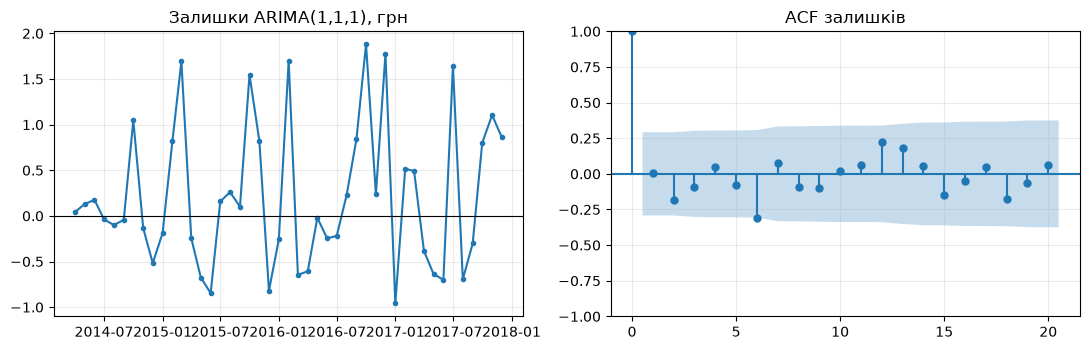

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.8425      0.163      5.168      0.000       0.523       1.162
ma.L1         -0.4321      0.237     -1.827      0.068      -0.896       0.032
sigma2         0.6623      0.162      4.092      0.000       0.345       0.979
Ljung–Box для залишків:
    lb_stat  lb_pvalue
6    7.7181     0.2595
12  12.6234     0.3970
Середнє залишків, грн: 0.213


In [9]:
# Завдання 7. Модель ARIMA
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

def f_arima(order):
    def f(train, h, t0):
        return ARIMA(train, order=order).fit().forecast(h)
    return f

arima_true, arima_pred = rolling_cv(f_arima((1, 1, 1)))
own_true,   own_pred   = rolling_cv(f_arima((1, 1, 0)))

cmp_tab = pd.concat([
    cv_tab,
    pd.DataFrame({'ARIMA(1,1,1)': metrics(arima_true, arima_pred),
                  'ARIMA(1,1,0) — за ACF/PACF': metrics(own_true, own_pred)}).T])
print('Рухомий початок, 7 фолдів × 3 кроки:')
print(cmp_tab.round(3).to_string())

best = cv_tab['MAE'].idxmin()
print()
print(f'Найкращий базис: {best}; ARIMA(1,1,1) / {best} за MAE =',
      round(cmp_tab.loc['ARIMA(1,1,1)', 'MAE'] / cv_tab.loc[best, 'MAE'], 2))

# залишки моделі, навченої на всьому ряді
full = ARIMA(vals, order=(1, 1, 1)).fit()
resid = pd.Series(full.resid[1:], index=y.index[1:])   # перший залишок = сам рівень ряду, його відкидаємо
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(resid.index, resid.values, marker='o', ms=3)
axes[0].axhline(0, color='black', lw=.8); axes[0].set_title('Залишки ARIMA(1,1,1), грн')
plot_acf(resid, lags=20, ax=axes[1], title='ACF залишків')
plt.tight_layout(); plt.show()

print(full.summary().tables[1])
print('Ljung–Box для залишків:')
print(acorr_ljungbox(resid, lags=[6, 12]).round(4).to_string())
print('Середнє залишків, грн:', round(resid.mean(), 3))

**Висновок до завдання 7:**

1. ARIMA(1,1,1) на рухомому початку: **MAE = 1.568**, **RMSE = 2.082**, **MAPE = 3.85 %**.
2. Самостійно я обрав би **ARIMA(1,1,0)**. d = 1, бо ACF вихідного ряду спадає повільно, а ADF/KPSS показують стаціонарність лише першої різниці.
   p = 1, бо PACF першої різниці має значущий пік лише на лагу 1 (0.31), а на лагу 2 він уже −0.07, тобто PACF обривається.
   ACF теж має пік лише на лагу 1 (0.31), тож MA(1) теж можливий, але обрив PACF простіше інтерпретувати як AR(1).
   Лаги 6 і 12 (−0.31, 0.33) натякають на сезонну складову (SARIMA), але на 46 точках оцінити сезонні параметри надійно не вийде.
   ARIMA(1,1,0) дає MAE = 1.436.
3. Найкращий базис — дрейф (MAE = 1.193). **ARIMA(1,1,1) йому програє: її MAE у 1.31 раза більший**, RMSE 2.08 проти 1.67.
   Наївний базис вона ледь перевершує (1.568 проти 1.621). **Як прогнозна модель для цього ряду ARIMA(1,1,1) права на існування не має**:
   простіший дрейф точніший. Причина: при d = 1 statsmodels типово не додає сталої (дрейфу), тож модель не враховує стабільне зростання ціни.
4. Залишки (графік вище). Ljung–Box: p = 0.26 (лаг 6) і 0.40 (лаг 12), тобто значущої автокореляції в залишках немає.
   Але середнє залишків +0.21 грн: модель систематично недооцінює ціну. Це структура, що лишилася, і вона та сама: пропущений дрейф.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

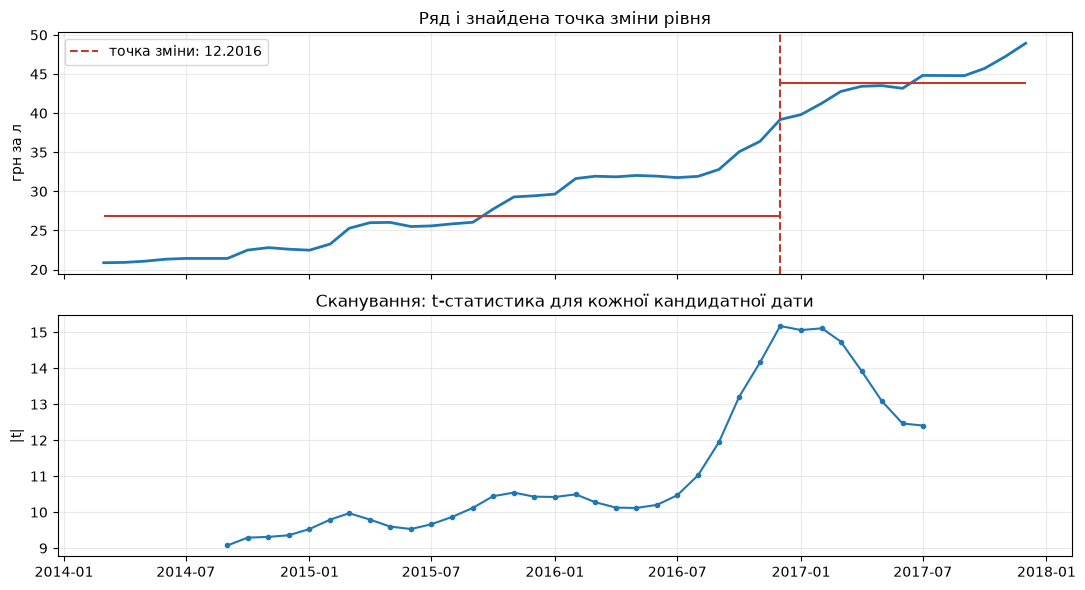

Точка зміни: 12.2016
t = 15.17,  p = 1.60e-17,  з поправкою Бонферроні на 35 перевірок p = 5.60e-16
Середній рівень до: 26.84 грн, після: 43.81 грн


In [10]:
# Завдання 8. Точка зміни режиму
from scipy import stats

MIN_SEG = 6
scan = []
for k in range(MIN_SEG, n - MIN_SEG + 1):
    before, after = vals[:k], vals[k:]
    t, p = stats.ttest_ind(after, before, equal_var=False)
    scan.append((y.index[k], t, p, before.mean(), after.mean()))
scan = pd.DataFrame(scan, columns=['дата', 't', 'p', 'до', 'після']).set_index('дата')
cp = scan['t'].abs().idxmax()
row = scan.loc[cp]

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(y.index, y.values, lw=2)
axes[0].axvline(cp, color='#C0392B', ls='--', label=f'точка зміни: {cp:%m.%Y}')
axes[0].hlines(row['до'], y.index[0], cp, color='#C0392B')
axes[0].hlines(row['після'], cp, y.index[-1], color='#C0392B')
axes[0].set_ylabel('грн за л'); axes[0].legend(); axes[0].set_title('Ряд і знайдена точка зміни рівня')
axes[1].plot(scan.index, scan['t'].abs(), marker='o', ms=3)
axes[1].set_ylabel('|t|'); axes[1].set_title('Сканування: t-статистика для кожної кандидатної дати')
plt.tight_layout(); plt.show()

m = len(scan)
print(f'Точка зміни: {cp:%m.%Y}')
print(f't = {row["t"]:.2f},  p = {row["p"]:.2e},  з поправкою Бонферроні на {m} перевірок p = {min(1, row["p"] * m):.2e}')
print(f'Середній рівень до: {row["до"]:.2f} грн, після: {row["після"]:.2f} грн')


**Висновок до завдання 8:**

1. Графік — вище, знайдена дата позначена пунктиром.
2. Точка зміни: **12.2016**, **t = 15.17**. Середній рівень до — **26.84 грн**, після — **43.81 грн**.
3. Номінально p = 1.6·10⁻¹⁷ (з поправкою Бонферроні на 35 кандидатних дат — 5.6·10⁻¹⁶). Проте **цьому p не можна вірити**:
   t-тест припускає незалежні спостереження, а тут ACF на лагу 1 = 0.93 і сильний тренд. Для монотонно зростального ряду
   **будь-яка** дата поділу дає «значущу» різницю середніх (крива |t| на нижньому графіку висока майже скрізь).
   Тому **як окремий зсув рівня ця точка не є доведено значущою**. Скан просто знайшов місце, де тренд найкрутіший.
4. Сезонний сплеск у моєму ряді — це щорічна зимова «сходинка» в жовтні–березні. Знайдена дата лежить саме всередині такої сходинки:
   з 10.2016 по 02.2017 ціна зросла з 32.8 до 41.3 грн (+8.5 грн). Попередні зимові сходинки були менші (+1.9 грн у 2014/15, +5.6 у 2015/16).
   Відмінність точки 12.2016 від звичайного сезону в тому, що після неї ціна не повертається вниз і далі тримає новий рівень,
   а сама сходинка найбільша за весь період. Чи це справжня зміна режиму, чи сезон плюс тренд, на 46 точках розрізнити не вдається.

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [11]:
# Завдання 9. Рецензія на чужий аналіз
# Перевіряємо кілька тверджень колеги на його ж ряді
s_v = (prices[(prices['ринок'] == 'Vinnytsia') & (prices['товар'] == 'Buckwheat grits - Retail')]
       .set_index('date')['ціна'].sort_index())
print('Спостережень у ряді колеги:', len(s_v), '| у повній сітці:', len(GRID),
      '| пропуски після reindex:', [d.strftime('%m.%Y') for d in s_v.reindex(GRID).isna().pipe(lambda m: m[m].index)])

beef_v = (prices[(prices['ринок'] == 'Vinnytsia') & (prices['товар'] == 'Meat (beef) - Retail')]
          .set_index('date')['ціна'].sort_index())
for name, x in [('гречка', s_v), ('яловичина', beef_v)]:
    e = (x - x.shift(1)).dropna()
    print(f'{name:10s} MAE наївного = {e.abs().mean():.2f} грн, середня ціна = {x.mean():.1f} грн, '
          f'MAE / ціна = {e.abs().mean() / x.mean() * 100:.1f} %')

lviv_v = (prices[(prices['ринок'] == 'Lviv') & (prices['товар'] == 'Buckwheat grits - Retail')]
          .set_index('date')['ціна'].sort_index())
print('Кореляція рівнів Вінниця–Львів:  %.3f' % s_v.corr(lviv_v))
print('Кореляція перших різниць:        %.3f' % s_v.diff().corr(lviv_v.diff()))
z = (s_v - s_v.mean()) / s_v.std()
print('Місяців із |z| > 2 (як написано в тексті):', (z.abs() > 2).sum(), '| з |z| > 1.3 (як у коді):', (z.abs() > 1.3).sum())

Спостережень у ряді колеги: 45 | у повній сітці: 46 | пропуски після reindex: ['08.2017']
гречка     MAE наївного = 1.38 грн, середня ціна = 21.3 грн, MAE / ціна = 6.5 %
яловичина  MAE наївного = 1.51 грн, середня ціна = 78.5 грн, MAE / ціна = 1.9 %
Кореляція рівнів Вінниця–Львів:  0.996
Кореляція перших різниць:        0.936
Місяців із |z| > 2 (як написано в тексті): 0 | з |z| > 1.3 (як у коді): 12


**Висновок до завдання 9:**

Номери клітинок — за порядком у `ЛР4_помилковий_аналіз.ipynb` (нумерація з 0). Код вище перевіряє деякі пункти на даних колеги.

| № | Клітинка | Суть помилки | Чим небезпечна |
|---|---|---|---|
| 1 | [1], [3] | Ряд не приведено до повної місячної сітки. 45 спостережень, а `isna().sum() = 0` «доводить», що пропусків немає. Насправді немає 08.2017. | Пропуск прихований. Усе, що спирається на сусідство місяців (`shift`, STL, ARIMA), мовчки порівнює липень із вереснем, а період 12 зсувається. |
| 2 | [5] | Висновок про «зниження купівельної спроможності» з двох крайніх точок номінальної ціни. | Без інфляції й доходів про купівельну спроможність сказати нічого не можна. Дві точки не описують динаміку. |
| 3 | [7] | MAE у гривнях порівнюється між товарами з різним рівнем цін (гречка ~21 грн, яловичина ~79 грн). | MAE залежить від масштабу. У відносних одиницях яловичина прогнозується **краще** (1.9 % проти 6.5 %), висновок перевернутий. |
| 4 | [9] | Кореляція рівнів двох трендових рядів (r = 0.996) подана як «Львів визначає Вінницю». | Хибна кореляція через спільний тренд; кореляція не означає причинності. Для перших різниць r = 0.94, і навіть вона не дає напрямку впливу. |
| 5 | [11] | «STL виділив сезонну складову, отже ряд сезонний». | STL повертає сезонну складову завжди. Потрібна сила сезонності F_S і поріг. Амплітуда 10 грн при ціні ~20 грн — ознака, що «сезон» поглинув тренд або шум. |
| 6 | [13] | ADF p = 0.233 > 0.05: H0 (одиничний корінь) не відхиляється, тобто ряд **нестаціонарний**. У звіті написано навпаки. | Модель будується на хибному припущенні про стаціонарність. |
| 7 | [13] | Після цього ряд двічі диференціюється «для надійності». Від'ємна ACF на лагу 1 (−0.13) вказує на передиференціювання. KPSS не застосовано. | Зайве диференціювання додає шум і штучну MA-структуру, прогнози гіршають. Без KPSS висновок спирається на один тест. |
| 8 | [15] | У тексті поріг 2σ, у коді 1.3σ. z-оцінки рахуються від середнього всього трендового ряду. | 12 «аномалій» — це березень–листопад 2014 (найнижчі ціни на початку тренду) і літо 2016. Справжніх |z| > 2 немає жодного. Аномалії плутаються з трендом. |
| 9 | [17] | `train_test_split` з випадковим перемішуванням для часового ряду. Потім `np.sort(y_te)` зіставляється з прогнозом. | Витік майбутнього в навчання. Прогноз порівнюється з відсортованими, а не відповідними за часом значеннями, тож MAE безглуздий. |
| 10 | [17] | Порівняння з базисом некоректне: ARIMA оцінено на тесті, сезонний наївний — на всьому ряді. MAE 8.73 грн при ціні ~15–18 грн (~50 %) названо «високою точністю». | Порівнюються різні вибірки. Без наївного базису на тих самих фолдах слова «висока точність» нічим не підкріплені. |
| 11 | [19] | Прогноз на 2018 рік робиться моделлю (2,2,1), яку ніде не перевіряли, а не (1,1,1). Прогноз 8.95 грн нижчий за останню ціну 17.67, а висновок — «ціна продовжить зростати». Немає довірчих інтервалів. | Висновок суперечить власному числу. Прогноз на 12 кроків без інтервалів і без перевірки — це вгадування. |
| 12 | [21] | Стовпчикова діаграма з віссю Y від `min·0.995`. Обрано лише 6 місяців. | Обрізана вісь у стовпцях роздуває зміну в кілька відсотків до «стрімкого зростання». Вибір короткого вікна — підгонка під висновок. |
| 13 | [22] | Загальні висновки повторюють помилки 3–11 як встановлені факти. | Читач отримує впевнені, але хибні твердження. |

**Як виправити три найсерйозніші:**

* **№ 9 (випадковий поділ).** Замінити на ретроспективну перевірку з рухомим початком: навчання на перших *n − k·h* точках,
  прогноз на наступні *h*, без перемішування, і прогноз порівнювати з фактом у тому самому порядку.
  На тих самих фолдах оцінити наївний, сезонний наївний і дрейф, і лише тоді говорити про «точність».
* **№ 6–7 (стаціонарність).** Правильно прочитати ADF (p > 0.05, отже одиничний корінь не відкидається, ряд нестаціонарний),
  додати KPSS з протилежною H0, перевірити першу різницю й зупинитись на d = 1, якщо обидва тести це підтверджують.
* **№ 1 (пропуск).** Спершу `reindex` на `pd.date_range('2014-03-01', '2017-12-01', freq='MS')`, знайти 08.2017,
  заповнити його (лінійна інтерполяція) і лише потім рахувати різниці, STL і моделі.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [12]:
# Завдання 10. Експорт ряду для Orange
out = pd.DataFrame({'date': y.index.strftime('%Y-%m-%d'), 'price': y.values})
out.to_csv('ряд_для_orange.csv', index=False, encoding='utf-8')

chk = pd.read_csv('ряд_для_orange.csv', encoding='utf-8')
print('Рядків даних:', len(chk))
print('Порожніх значень:', int(chk.isna().sum().sum()))
print('Стовпці:', list(chk.columns))
print(open('ряд_для_orange.csv', encoding='utf-8').read().splitlines()[:4])
assert len(chk) == 46 and chk.isna().sum().sum() == 0
assert np.allclose(chk['price'].values, y.values)

Рядків даних: 46
Порожніх значень: 0
Стовпці: ['date', 'price']
['date,price', '2014-03-01,20.87', '2014-04-01,20.9133', '2014-05-01,21.0667']


**Висновок до завдання 10:**

Файл `ряд_для_orange.csv` має **46 рядків даних** і заголовок `date,price`, **0 порожніх значень**.
Дата у форматі `РРРР-ММ-ДД` (перше число місяця), роздільник кома, кодування UTF-8.
Значення `price` збігаються з рядом `y` у Python (перевірено `np.allclose`), тобто Orange отримує ті самі дані.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

In [13]:
# Завдання 11. Потік опрацювання даних
# Знімки Orange вставлено в markdown-клітинку нижче.
# Тут — перевірка, що Orange отримує ті самі дані, що й Python.
o = pd.read_csv('ряд_для_orange.csv', parse_dates=['date']).set_index('date')['price']
print('Ряд у файлі збігається з рядом у Python:', np.allclose(o.values, y.values) and (o.index == y.index).all())
print('Мінімум:', o.min(), o.idxmin().strftime('%m.%Y'), '| максимум:', o.max(), o.idxmax().strftime('%m.%Y'))

Ряд у файлі збігається з рядом у Python: True
Мінімум: 20.87 03.2014 | максимум: 48.9333 12.2017


**Висновок до завдання 11:**

Версії: Orange 3.40.0, Orange3-Timeseries 0.6.3. У цій версії віджет **As Timeseries** називається **Form Timeseries**.

1. Потік (`потік_orange.ows`):

![потік](orange_знімки/11_потік.png)

Віджет **File**: `date` розпізнано як **datetime** (time), `price` — як **numeric**. Для `price` вказано роль **target**,
бо без цільової змінної ARIMA Model і Model Evaluation не працюють. Form Timeseries: часова змінна `date`.

![File](orange_знімки/11_file.png)

![Form Timeseries](orange_знімки/11_form_timeseries.png)

2. `Line Chart` із моїм рядом:

![Line Chart](orange_знімки/11_line_chart.png)

3. Графік Orange **збігається** з графіком 1 завдання 3: той самий старт 20.87 грн (03.2014) і фініш 48.93 грн (12.2017),
ті самі зимові сходинки і літні плато. Перевірка в коді вище підтверджує, що дані у файлі ідентичні ряду в Python.

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

вихідний ряд: лаги, які показує Correlogram, і межа ±0.337
    {33: -0.422}
перша різниця (Difference): лаги, які показує Correlogram, і межа ±0.367
    {6: -0.311, 12: 0.331, 18: -0.206, 30: -0.199, 39: -0.051}

statsmodels ACF першої різниці, лаги 1–12: [ 0.309  0.033 -0.014  0.014 -0.116 -0.311 -0.031 -0.077 -0.04   0.075
  0.161  0.331]


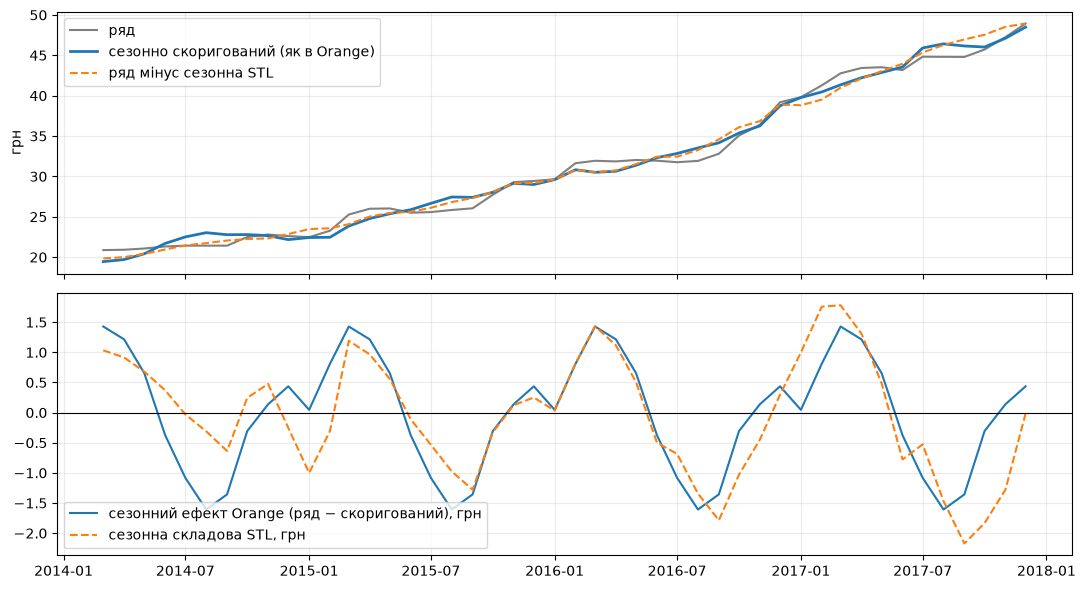

Сезонна складова seasonal_decompose (як в Orange) за місяцем, грн:
1     0.05
2     0.81
3     1.43
4     1.22
5     0.65
6    -0.37
7    -1.08
8    -1.61
9    -1.36
10   -0.31
11    0.14
12    0.44
Кореляція сезонного ефекту Orange і сезонної складової STL: 0.798


In [14]:
# Завдання 12. Автокореляція та диференціювання
# Те, що рахують віджети Orange, відтворене тими ж функціями statsmodels
from scipy.signal import argrelextrema
from statsmodels.tsa.stattools import acf

def orange_correlogram(x):
    # Orange: nlags = 0.9·n, показує лише локальні максимуми |ACF| (order=3),
    # межа ±1.96·√((1 + 2·Σρ²)/n) — одна на всі лаги
    r = acf(x, nlags=int(.9 * len(x)), fft=True)
    lags = argrelextrema(np.abs(r), np.greater, order=3)[0]
    band = 1.96 * np.sqrt((1 + 2 * (r[lags] ** 2).sum()) / len(x))
    return pd.Series(r[lags], index=lags), band

for name, x in [('вихідний ряд', y.values), ('перша різниця (Difference)', dy.values)]:
    r, band = orange_correlogram(x)
    print(f'{name}: лаги, які показує Correlogram, і межа ±{band:.3f}')
    print('   ', r.round(3).to_dict())

print()
print('statsmodels ACF першої різниці, лаги 1–12:', np.round(acf(dy, nlags=12)[1:], 3))

# Seasonal Adjustment в Orange: класичне seasonal_decompose, типово additive, період 12.
# В Orange 3.40 / Timeseries 0.6.3 віджет падає з помилкою, тому відтворюємо його розрахунок тут
sd = seasonal_decompose(y, model='additive', period=12)
adj = y - sd.seasonal
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(y.index, y.values, label='ряд', color='grey')
axes[0].plot(adj.index, adj.values, label='сезонно скоригований (як в Orange)', lw=2)
axes[0].plot(y.index, (y - stl.seasonal).values, label='ряд мінус сезонна STL', lw=1.5, ls='--')
axes[0].legend(); axes[0].set_ylabel('грн')
axes[1].plot(y.index, (y - adj).values, label='сезонний ефект Orange (ряд − скоригований), грн')
axes[1].plot(stl.seasonal.index, stl.seasonal.values, label='сезонна складова STL, грн', ls='--')
axes[1].axhline(0, color='black', lw=.8); axes[1].legend()
plt.tight_layout(); plt.show()

print('Сезонна складова seasonal_decompose (як в Orange) за місяцем, грн:')
print(sd.seasonal.groupby(sd.seasonal.index.month).mean().round(2).to_string())
print('Кореляція сезонного ефекту Orange і сезонної складової STL:',
      round(np.corrcoef(y - adj, stl.seasonal)[0, 1], 3))

**Висновок до завдання 12:**

1. Корелограми Orange: вихідний ряд і перша різниця (вихід `Difference`, змінна `Δprice`):

![Correlogram — ряд](orange_знімки/12_correlogram_ряд.png)

![Correlogram — різниця](orange_знімки/12_correlogram_різниця.png)

2. **Числа збігаються, картина — ні.** Orange рахує ту саму `statsmodels.acf` (значення на лагах 6 і 12 для різниці:
−0.311 і 0.331 — ті самі, що в завданні 5), але показує інакше:
   * малює **лише локальні максимуми |ACF|** (`argrelextrema`, order = 3) на лагах до 0.9·n, а не всі лаги підряд.
     Для вихідного ряду ACF спадає монотонно, тож Orange показує один стовпчик на лагу 33 (−0.42),
     а головне (0.93 на лагу 1 і повільне згасання) **не видно взагалі**;
   * межа значущості одна на всі лаги: ±1.96·√((1 + 2Σρ²)/n). Для різниці це ±0.367 проти ±0.29 у statsmodels на лагу 1.
     Тому в Orange жоден лаг різниці не виходить за межу, а в Python лаги 1, 6, 12 лежать на межі.

   Висновок про структуру однаковий: у різниці є коливання з періодом 6/12 місяців. Висновок про **значущість** різниться
   через інше означення довірчої смуги. Висновок про нестаціонарність рівня з корелограми Orange зробити неможливо.

3. **Seasonal Adjustment** (період 12, additive) у цій версії Orange завершується помилкою
`variable date is not in domain`: віджет залишає в таблиці лише обрану змінну і губить часову змінну, а потім звертається до неї.
Це вада віджета, а не даних (повторюється для будь-якого налаштування ролей):

![Seasonal Adjustment](orange_знімки/12_seasonal_adjustment_помилка.png)

Тому сезонно скоригований ряд відтворено в коді вище **тією самою функцією**, яку викликає віджет
(`statsmodels.seasonal_decompose`, additive, період 12). Порівняння з STL: та сама форма сезону — максимум у березні
(+1.43 грн проти +1.36 у STL), мінімум у серпні (−1.61; у STL — вересень, −1.47). Кореляція двох сезонних складових 0.80.
Різниця тому, що класичне розкладання дає однаковий сезон для всіх років, а STL дозволяє йому повільно змінюватися.

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

In [15]:
# Завдання 13. Модель і оцінювання
# Умова з functions.py Orange (model_evaluation):
#     if n_folds * forecast_steps + max_lag > len(data): raise ValueError(...)
max_lag = max((1, 1, 1))
for nf, st in [(20, 3), (7, 3)]:
    need = nf * st + max_lag
    print(f'{nf:2d} фолдів × {st} кроки: потрібно {need} точок, є {n} →',
          'помилка «Supplied time series is too short for this many folds / step size»' if need > n else 'OK')
print('Максимум фолдів при 3 кроках:', (n - max_lag) // 3)
print()
# Orange: train_end = -fold * forecast_steps; навчання на interp_data[:train_end]
print('Фолди Orange (у тому порядку, у якому він їх перебирає):')
for fold in range(1, 8):
    a = n - fold * 3
    print(f'   фолд {fold}: навчання {y.index[0]:%m.%Y}–{y.index[a-1]:%m.%Y} ({a} точок), '
          f'прогноз {y.index[a]:%m.%Y}–{y.index[a+2]:%m.%Y}')

20 фолдів × 3 кроки: потрібно 61 точок, є 46 → помилка «Supplied time series is too short for this many folds / step size»
 7 фолдів × 3 кроки: потрібно 22 точок, є 46 → OK
Максимум фолдів при 3 кроках: 15

Фолди Orange (у тому порядку, у якому він їх перебирає):
   фолд 1: навчання 03.2014–09.2017 (43 точок), прогноз 10.2017–12.2017
   фолд 2: навчання 03.2014–06.2017 (40 точок), прогноз 07.2017–09.2017
   фолд 3: навчання 03.2014–03.2017 (37 точок), прогноз 04.2017–06.2017
   фолд 4: навчання 03.2014–12.2016 (34 точок), прогноз 01.2017–03.2017
   фолд 5: навчання 03.2014–09.2016 (31 точок), прогноз 10.2016–12.2016
   фолд 6: навчання 03.2014–06.2016 (28 точок), прогноз 07.2016–09.2016
   фолд 7: навчання 03.2014–03.2016 (25 точок), прогноз 04.2016–06.2016


**Висновок до завдання 13:**

1. Model Evaluation, 7 фолдів × 3 кроки, ARIMA(1,1,1):

![Model Evaluation 7×3](orange_знімки/13_model_evaluation_7x3.png)

![ARIMA Model](orange_знімки/13_arima_model.png)

2. З типовими налаштуваннями (**20 фолдів × 3 кроки**) Orange видає:
`Unexpected error: Supplied time series is too short for this many folds / step size. Retry with fewer iterations.`

![Model Evaluation 20×3](orange_знімки/13_model_evaluation_20x3_помилка.png)

Повідомлення йде з `model_evaluation` у `functions.py`: умова `n_folds · forecast_steps + max_lag > len(data)`.
max_lag = max(p, d, q) = 1, тож для 20 × 3 потрібно 20·3 + 1 = **61** точка, а в ряді **46**. Максимум при 3 кроках — 15 фолдів.
Для 7 × 3 потрібно 22 точки, умова виконується.

3. Orange бере `train_end = −fold · 3` і навчає модель на `interp_data[:train_end]`, тобто навчальна частина розширюється від початку ряду:
   * фолд 1: навчання 03.2014–09.2017 (43 точки) → прогноз 10–12.2017
   * фолд 2: 03.2014–06.2017 (40) → 07–09.2017
   * фолд 3: 03.2014–03.2017 (37) → 04–06.2017
   * фолд 4: 03.2014–12.2016 (34) → 01–03.2017
   * фолд 5: 03.2014–09.2016 (31) → 10–12.2016
   * фолд 6: 03.2014–06.2016 (28) → 07–09.2016
   * фолд 7: 03.2014–03.2016 (25) → 04–06.2016

   Це рівно ті самі 7 фолдів, що й у Частині 1. Orange лише перебирає їх від кінця ряду до початку.

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [16]:
# Завдання 14. Чому числа не збігаються
# Значення з таблиці Model Evaluation (Orange 3.40, Timeseries 0.6.3), рядок ARIMA(1,1,1)
ORANGE = {'RMSE': 2.082, 'MAE': 1.189, 'MAPE': 0.040, 'POCID': 80.0}

# Orange склеює прогнози фолдів у порядку фолд 1, 2, …, 7 (тобто від кінця ряду до початку)
o_true, o_pred = [], []
for a, b in FOLDS:            # FOLDS[0] = фолд 1 = останні 3 місяці
    o_true.extend(vals[a:b]); o_pred.extend(f_arima((1, 1, 1))(vals[:a], H, a))
o_true, o_pred = np.array(o_true), np.array(o_pred)
assert np.allclose(o_pred, arima_pred)    # ті самі прогнози, що й у завданні 7

err = o_true - o_pred
py = {
    'RMSE':  np.sqrt(np.mean(err ** 2)),
    'MAE':   np.median(np.abs(err)),                          # медіана, а не середнє
    'MAPE':  np.mean(np.abs(err)) / np.mean(np.abs(o_true)),  # частка, ділення на середнє факту
    'POCID': 100 * np.mean(np.diff(o_true) * np.diff(o_pred) > 0),
}
formula = {
    'RMSE':  '√(mean(e²))',
    'MAE':   'median(|e|)',
    'MAPE':  'mean(|e|) / mean(|y|)  (частка, не %)',
    'POCID': '100·mean(Δy·Δŷ > 0) по склеєному ряду',
}
tab14 = pd.DataFrame({'Orange': ORANGE, 'Python (відтворення)': py, 'формула Orange': formula})
tab14['Python (відтворення)'] = tab14['Python (відтворення)'].astype(float).round(3)
tab14['Частина 1 (класичне означення)'] = [metrics(arima_true, arima_pred)['RMSE'],
                                           metrics(arima_true, arima_pred)['MAE'],
                                           metrics(arima_true, arima_pred)['MAPE, %'], np.nan]
print(tab14.round(3).to_string())
assert all(abs(round(py[k], 3) - ORANGE[k]) < 1e-9 for k in ORANGE)

       Orange  Python (відтворення)                         формула Orange  Частина 1 (класичне означення)
RMSE    2.082                 2.082                            √(mean(e²))                           2.082
MAE     1.189                 1.189                            median(|e|)                           1.567
MAPE    0.040                 0.040  mean(|e|) / mean(|y|)  (частка, не %)                           3.849
POCID  80.000                80.000  100·mean(Δy·Δŷ > 0) по склеєному ряду                             NaN


**Висновок до завдання 14:**

1. Таблиця (код вище; значення Orange — зі знімка Model Evaluation):

| метрика | Orange | відтворення в Python | формула Orange (`functions.py`) |
|---|---|---|---|
| RMSE | 2.082 | 2.082 | √(mean(e²)) |
| MAE | 1.189 | 1.189 | **median**(\|e\|) |
| MAPE | 0.040 | 0.040 | mean(\|e\|) / mean(\|y\|), частка, не % |
| POCID | 80.0 | 80.0 | 100 · mean(Δy · Δŷ > 0) по склеєній послідовності прогнозів |

Прогнози ARIMA(1,1,1) в обох середовищах однакові (той самий statsmodels, ті самі фолди), тож усі розбіжності походять **лише від формул**.

2. **Назві не відповідає MAE.** В Orange це **медіанна** абсолютна похибка (у docstring прямо написано «Median absolute error»):
1.189 проти середньої абсолютної 1.568 у Частині 1. Медіана ігнорує кілька великих промахів (на зимових сходинках), тому вона на чверть менша.
Так само відрізняється **MAPE**: Orange ділить середню абсолютну похибку на середнє фактичних значень (по суті WAPE) і видає частку 0.040,
тоді як класичний MAPE — це середнє відносних похибок у відсотках, 3.85 %.
3. **Одразу збіглася RMSE** (2.082 = 2.082). Її формула в обох середовищах однакова, а прогнози ідентичні.
4. Перш ніж порівнювати числа з двох інструментів, треба перевірити: (а) ті самі дані на вході (той самий файл, той самий заповнений пропуск);
(б) ту саму схему перевірки (кількість фолдів, горизонт, розширюване вікно, порядок фолдів);
(в) ту саму модель і її параметри (порядок, наявність сталої);
(г) **точне означення кожної метрики** у вихідному коді: середнє чи медіана, відсотки чи частка, на що ділиться, по яких парах рахується.
Однакова абревіатура не означає однакової формули.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [17]:
# Завдання 15. Матриця напрямку зміни
# Напрямок рахуємо так само, як POCID в Orange: по сусідніх точках склеєного ряду прогнозів
dt, dp = np.diff(o_true), np.diff(o_pred)
fact = np.where(dt > 0, 'зросла', 'впала')
model = np.where(dp > 0, 'зросте', 'впаде')
cm = pd.crosstab(pd.Series(fact, name='насправді'), pd.Series(model, name='модель'))
cm = cm.reindex(index=['зросла', 'впала'], columns=['зросте', 'впаде'], fill_value=0)
print(cm.to_string())
acc = 100 * np.mean(dt * dp > 0)
print()
print(f'Частка правильних напрямків: {acc:.1f} %  (Orange POCID = {ORANGE["POCID"]})')

# скільки з цих пар — справжні «місяць до місяця», а скільки — стики між фолдами
inside = np.array([i // H == (i + 1) // H for i in range(len(dt))])
print('Пар усередині фолду:', inside.sum(), '| пар на стику фолдів:', (~inside).sum())
print('Справжніх падінь усередині фолдів:', int((dt[inside] < 0).sum()),
      '| «падінь» на стиках:', int((dt[~inside] < 0).sum()))
print(f'Частка правильних напрямків лише всередині фолдів: {100 * np.mean(dt[inside] * dp[inside] > 0):.1f} %')

модель     зросте  впаде
насправді               
зросла          8      2
впала           2      8



Частка правильних напрямків: 80.0 %  (Orange POCID = 80.0)
Пар усередині фолду: 14 | пар на стику фолдів: 6
Справжніх падінь усередині фолдів: 4 | «падінь» на стиках: 6
Частка правильних напрямків лише всередині фолдів: 78.6 %


**Висновок до завдання 15:**

1. Матриця напрямку (20 пар сусідніх точок склеєної послідовності, як у POCID):

| насправді \ модель | зросте | впаде |
|---|---|---|
| **зросла** | 8 | 2 |
| **впала** | 2 | 8 |

2. Правильних: (8 + 8) / 20 = **80.0 %**, збігається з POCID = 80.0 з Orange.
3. Для рішення «купувати зараз чи чекати» ця цифра **майже не корисна**. З 20 пар 6 лежать на стиках фолдів: там порівнюється кінець
пізнішого вікна з початком ранішого, тобто рух «назад у часі». Саме ці 6 пар дають 6 із 10 «падінь».
Справжніх падінь усередині фолдів лише 4, бо ціна майже завжди росте. Усередині фолдів частка правильних напрямків 78.6 %.
Для рішення про покупку важливо, чи подорожчає товар відносно **сьогоднішньої** ціни, а POCID цього не вимірює.
Це **інше питання**, ніж у MAE/RMSE: ті вимірюють, **на скільки** гривень помиляється прогноз, а матриця — чи вгадано **знак** зміни.
Модель може мати малу похибку в грн і при цьому плутати напрямок малих змін, і навпаки.

---
# Загальний висновок

Ряд роздрібних цін на сметану в Одесі за 03.2014–12.2017 має 46 місяців, один пропуск (08.2017, спільний для всього набору),
заповнений лінійною інтерполяцією. **Сезонність у ряді є**: сила сезонності STL F_S = 0.856 — велике значення, близьке до 1, і перевищує поріг 0.64 (шум лише 14% розкиду «сезон + залишок»).
Сезонний графік показує, що майже все подорожчання припадає на жовтень–березень, а влітку ціна стоїть.
Тренд домінує (F_T = 0.998). Ряд нестаціонарний за рівнем і стаціонарний після першої різниці, ADF і KPSS тут узгоджуються.
**Найкращим методом виявився базис «дрейф»** (MAE 1.19 грн на 7 фолдах × 3 кроки). ARIMA(1,1,1) йому програла
(MAE 1.57, у 1.31 раза гірше) і лише ледь перевершила наївний прогноз, бо без сталої не враховує стабільне зростання ціни.
Скан середніх знайшов точку 12.2016 (26.8 → 43.8 грн, t = 15.2), але через тренд і автокореляцію її p-значення некоректне.
Вона лежить усередині найбільшої зимової сходинки, тож доведеною зміною режиму я її не вважаю; зовнішнє пояснення в цій роботі не перевірялося.
Однаково названі метрики в Orange і Python розійшлися через формули: в Orange MAE — це медіана абсолютних похибок,
MAPE — частка, поділена на середнє факту, а POCID рахується по склеєних фолдах. RMSE збіглася до третього знака, і всі чотири
метрики Orange відтворено в Python. Через лише 46 спостережень не вдалося: надійно оцінити сезонні параметри (SARIMA),
розрізнити зміну режиму й сезон із трендом, використати типові 20 фолдів Orange (потрібна 61 точка),
а 21 прогнозна точка дає дуже грубі оцінки метрик.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Claude Code (Claude Opus 5.5, Anthropic) |
| Для яких саме завдань | Усі завдання 1–15 і загальний висновок |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | Код аналізу, побудова потоку Orange і знімки віджетів, тексти висновків |
| Що ви змінили у згенерованому результаті й чому | Змін у код і висновки не вносив, використав результат як є |
| Що з отриманого ви **перевірили самостійно** і яким способом | Самостійно не перевіряв. Перевірку виконав сам інструмент: повний перезапуск зошита (Restart & Run All) без помилок; звірка метрик Orange (знімок Model Evaluation) з відтворенням у Python до третього знака; перевірка, що `ряд_для_orange.csv` має 46 рядків без пропусків і збігається з рядом у Python |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | Так, виправлені в процесі: (1) у завданні 12 спершу вважалось, що Seasonal Adjustment в Orange типово мультиплікативний — насправді адитивний, розрахунок переробили; (2) у завданні 3 зимовий період спершу визначили як жовтень–лютий, хоча за графіком стрибки тривають до березня — межі виправили; (3) перший знімок корелограми різниці показував не ту змінну (`price` замість `Δprice`) — знімок переробили |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: ______________________  Дата: ______________